# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer: I used **Forest Fires**, created by Paulo Cortez and Anibal Morais and published through the UCI Machine Learning Repository. Accessed November 5, 2026.

- Dataset: [UCI Forest Fires](https://archive.ics.uci.edu/dataset/162/forest+fires)
- Direct CSV: [forestfires.csv](https://archive.ics.uci.edu/ml/machine-learning-databases/forest-fires/forestfires.csv)
- Data dictionary: [forestfires.names](https://archive.ics.uci.edu/ml/machine-learning-databases/forest-fires/forestfires.names), section 7
- Citation: Cortez, P. and Morais, A. (2007). *Forest Fires* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D. CC BY 4.0.


**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer: Each row is a recorded forest fire with weather readings, map coordinates, and burned area for Montesinho park in northeast Portugal. The file has 517 rows. It is research data based on recorded fires and weather measurements, not a random sample of all days. The linked UCI dictionary does not give exact collection dates or the full collection procedure. The CSV gives month and weekday but no year or exact date, so this analysis does not make a year-by-year comparison.


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: I checked the course notebooks in Weeks 1 through 4 and the earlier lab work for Forest Fires and its filename. It was not used there. Earlier labs used flights, Iris plants, and Titanic passengers. This is a different source and topic.


## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
fires_df = pd.read_csv("data/forestfires.csv")


In [3]:
fires_df.head()


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [4]:
fires_df.tail()


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
512,4,3,aug,sun,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44
513,2,4,aug,sun,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29
514,7,4,aug,sun,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16
515,1,4,aug,sat,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00
516,6,3,nov,tue,79.5,3.0,106.7,1.1,11.8,31,4.5,0.0,0.00


In [5]:
fires_df.shape


(517, 13)

In [6]:
fires_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 55.7 KB


In [7]:
fires_df.isnull().sum()


X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| `X` | Park map x-coordinate from 1 to 9, not a measured distance | Spatial code | int64 | 0 |
| `Y` | Park map y-coordinate from 2 to 9, not a measured distance | Spatial code | int64 | 0 |
| `month` | Month code jan through dec | Categorical, month of year | str | 0 |
| `day` | Weekday code mon through sun | Categorical, day of week | str | 0 |
| `FFMC` | Fine Fuel Moisture Code in the Fire Weather Index system, index units | Quantitative | float64 | 0 |
| `DMC` | Duff Moisture Code in the Fire Weather Index system, index units | Quantitative | float64 | 0 |
| `DC` | Drought Code in the Fire Weather Index system, index units | Quantitative | float64 | 0 |
| `ISI` | Initial Spread Index in the Fire Weather Index system, index units | Quantitative | float64 | 0 |
| `temp` | Recorded temperature in degrees Celsius | Quantitative | float64 | 0 |
| `RH` | Relative humidity in percent | Quantitative | int64 | 0 |
| `wind` | Wind speed in km/h | Quantitative | float64 | 0 |
| `rain` | Outside rain, units listed as mm/m2 in the source dictionary | Quantitative | float64 | 0 |
| `area` | Burned area in hectares | Quantitative | float64 | 0 |


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer: I will group by month and compare August with September. The three measurements are temperature in degrees Celsius, relative humidity in percent, and wind speed in km/h. These measure different things, so they are not three versions of the same value. August and September are neighboring late-summer months, making this a useful seasonal comparison. The dictionary lists no missing values or special missing codes. Valid zeros in other columns are kept as zeros. No units are converted.


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the temperature distribution, in degrees Celsius, differ between August and September fire records in this dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I expect August to be warmer than September because it is earlier in the late-summer season. The ranges will probably overlap because weather changes from day to day.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use the August and September rows and the temp column. Each row is one fire record with its recorded temperature, not one unique day. Other months are left out to focus on these two neighboring months. Missing temperatures would be removed only from this comparison, but the file has none. Month codes aug and sep are labeled August and September in a separate analysis DataFrame. The original fires_df stays unchanged.


In [8]:
temperature_df = fires_df.loc[
    fires_df["month"].isin(["aug", "sep"]), ["month", "temp"]
].copy()
temperature_df = temperature_df.dropna(subset=["temp"])
temperature_df["month_name"] = temperature_df["month"].map({"aug": "August", "sep": "September"})
temperature_df.head()


,month,temp,month_name
5,aug,22.2,August
6,aug,24.1,August
7,aug,8.0,August
8,sep,13.1,September
9,sep,22.8,September


In [9]:
temperature_df["month_name"].value_counts().reindex(["August", "September"])


month_name
August       184
September    172
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


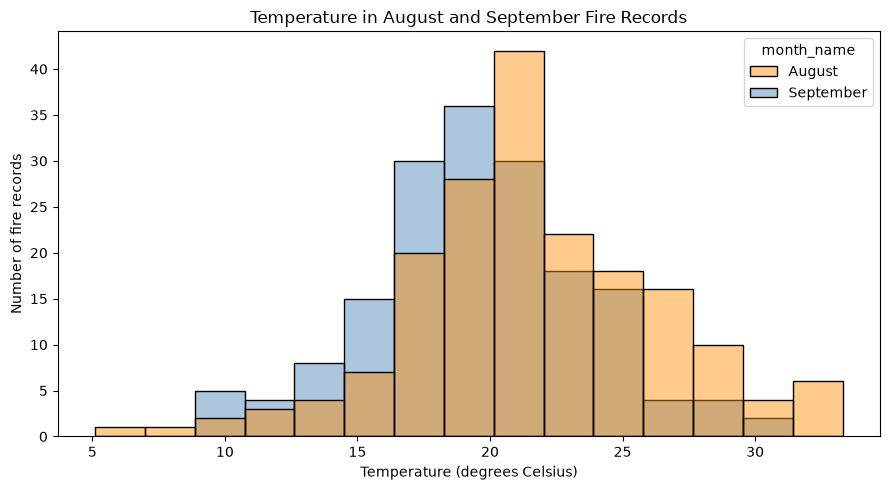

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=temperature_df, x="temp", hue="month_name",
    hue_order=["August", "September"], bins=15, common_bins=True,
    palette={"August": "darkorange", "September": "steelblue"}, alpha=0.45
)
plt.title("Temperature in August and September Fire Records")
plt.xlabel("Temperature (degrees Celsius)")
plt.ylabel("Number of fire records")
plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: August looks centered around 21 to 22 degrees Celsius, with most values around 15 to 27. September looks centered near 19 to 20, with most around 15 to 24. Both have one main peak and lots of overlap. August has a wider range, including a low value near 5 and highs above 30. There are 184 August records and 172 September records, so raw bar heights also reflect the slightly larger August group.


In [11]:
temperature_summary = temperature_df.groupby("month_name")["temp"].describe().reindex(["August", "September"])
temperature_summary.round(2)


,count,mean,std,min,25%,50%,75%,max
month_name,,,,,,,,
August,184.0,21.63,4.81,5.1,18.90,21.25,24.22,33.3
September,172.0,19.61,4.03,9.8,17.27,19.60,22.15,30.2


In [12]:
temperature_iqr = temperature_summary["75%"] - temperature_summary["25%"]
temperature_iqr


month_name
August       5.325
September    4.875
dtype: float64

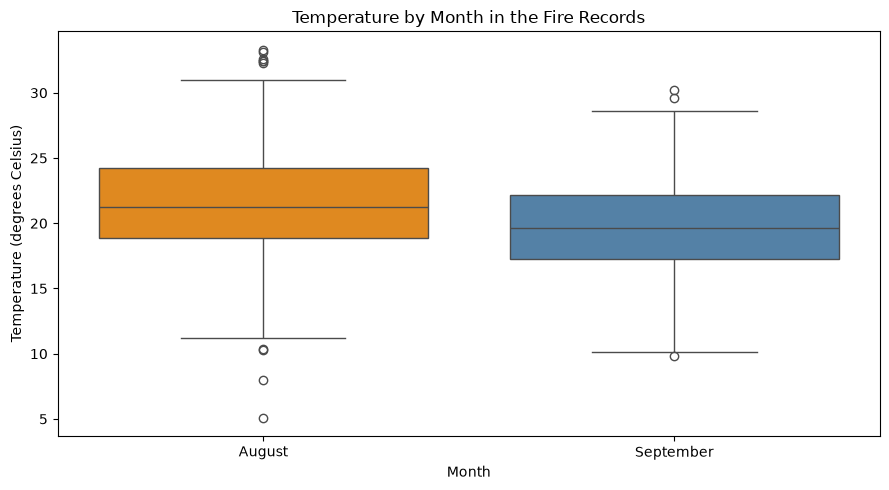

In [13]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=temperature_df, x="month_name", y="temp", hue="month_name",
    order=["August", "September"], hue_order=["August", "September"],
    palette={"August": "darkorange", "September": "steelblue"}, legend=False
)
plt.title("Temperature by Month in the Fire Records")
plt.xlabel("Month")
plt.ylabel("Temperature (degrees Celsius)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The numbers are close to those estimates. August's mean is 21.63 and median is 21.25 degrees Celsius, compared with 19.61 and 19.60 in September. August's middle 50% runs from 18.90 to 24.225 degrees, with an IQR of 5.325 degrees. September's runs from 17.275 to 22.15, with an IQR of 4.875 degrees. The boxes make the slightly higher August center easy to see. The histogram shows the overlap and shape better, while equal-width boxes hide the group sizes.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [14]:
temperature_df.groupby("month_name")["temp"].agg(["count", "min", "max"])


,count,min,max
month_name,,,
August,184,5.1,33.3
September,172,9.8,30.2


In [15]:
fires_df.loc[
    [temperature_df["temp"].idxmin(), temperature_df["temp"].idxmax()],
    ["X", "Y", "month", "day", "temp"]
]


,X,Y,month,day,temp
211,7,4,aug,sat,5.1
498,6,5,aug,tue,33.3


In [16]:
print("Original August and September rows:", fires_df["month"].isin(["aug", "sep"]).sum())
print("Rows used:", len(temperature_df))
print("Month labels used:", temperature_df["month_name"].unique())


Original August and September rows: 356
Rows used: 356
Month labels used: <ArrowStringArray>
['August', 'September']
Length: 2, dtype: str


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: If a temperature looked way too high or low, or the units were wrong, I'd want to check it. A negative number isn't always wrong because the temperatures are in Celsius. I checked the original data, and August really does have 5.1°C and 33.3°C. August goes from 5.1°C to 33.3°C and September goes from 9.8°C to 30.2°C, just like the plots. I also still have all 356 rows (184 for August and 172 for September), so I didn't remove anything. I can't tell if every reading was correct, only that it matches the file.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Among 184 August and 172 September fire records, August has a higher median temperature, 21.25 versus 19.60 degrees Celsius. Its IQR is also slightly wider, 5.325 versus 4.875 degrees. The distributions still overlap a lot. This supports the prediction of warmer August readings without showing that every August record is warmer.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: This only looks at temperatures when fires were recorded in this park. It doesn't show what the weather was like on every day in August or September, and it doesn't mean the temperature caused the fires. There aren't exact dates either, so some of these fires could have been on the same day.


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does relative humidity, measured in percent, differ between August and September fire records in this dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I expect August to have slightly lower humidity because hotter weather can be drier. I still expect a lot of overlap, since humidity also changes with local weather.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use August and September records with RH, the relative humidity percentage. Other months are excluded for the same seasonal comparison. There are no missing RH values, so all selected rows stay. Each row is one fire record, not a count of rainy days. Month labels are added only to humidity_df, leaving fires_df unchanged.


In [17]:
humidity_df = fires_df.loc[
    fires_df["month"].isin(["aug", "sep"]), ["month", "RH"]
].copy()
humidity_df = humidity_df.dropna(subset=["RH"])
humidity_df["month_name"] = humidity_df["month"].map({"aug": "August", "sep": "September"})
humidity_df.head()


,month,RH,month_name
5,aug,29,August
6,aug,27,August
7,aug,86,August
8,sep,63,September
9,sep,40,September


In [18]:
humidity_df["month_name"].value_counts().reindex(["August", "September"])


month_name
August       184
September    172
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


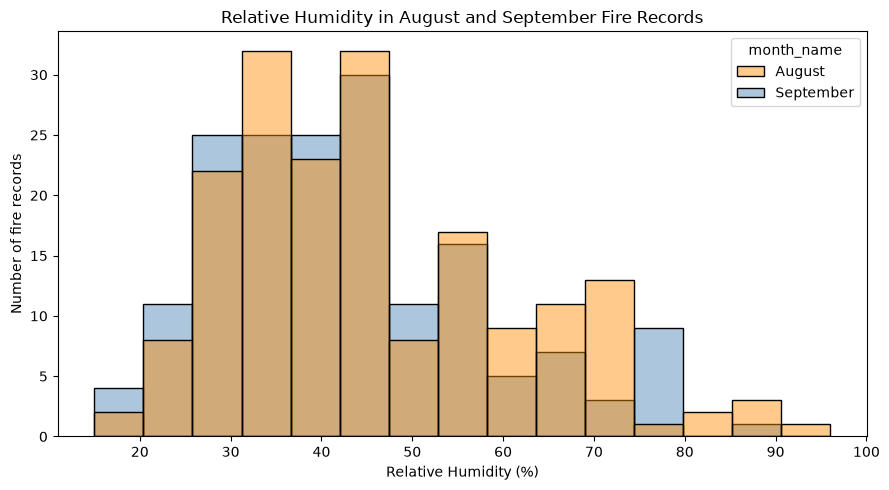

In [19]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=humidity_df, x="RH", hue="month_name",
    hue_order=["August", "September"], bins=15, common_bins=True,
    palette={"August": "darkorange", "September": "steelblue"}, alpha=0.45
)
plt.title("Relative Humidity in August and September Fire Records")
plt.xlabel("Relative Humidity (%)")
plt.ylabel("Number of fire records")
plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Both months have many readings around 30% to 50% humidity, with a longer tail toward high humidity. August looks slightly higher and more spread out, reaching the mid-90s. September reaches the mid-80s. The groups overlap heavily. August has 184 records and September 172, so slightly taller August bars do not by themselves show a higher percentage.


In [20]:
humidity_summary = humidity_df.groupby("month_name")["RH"].describe().reindex(["August", "September"])
humidity_summary.round(2)


,count,mean,std,min,25%,50%,75%,max
month_name,,,,,,,,
August,184.0,45.49,15.77,19.0,33.75,42.0,56.0,96.0
September,172.0,42.84,15.05,15.0,32.75,40.0,51.0,86.0


In [21]:
humidity_iqr = humidity_summary["75%"] - humidity_summary["25%"]
humidity_iqr


month_name
August       22.25
September    18.25
dtype: float64

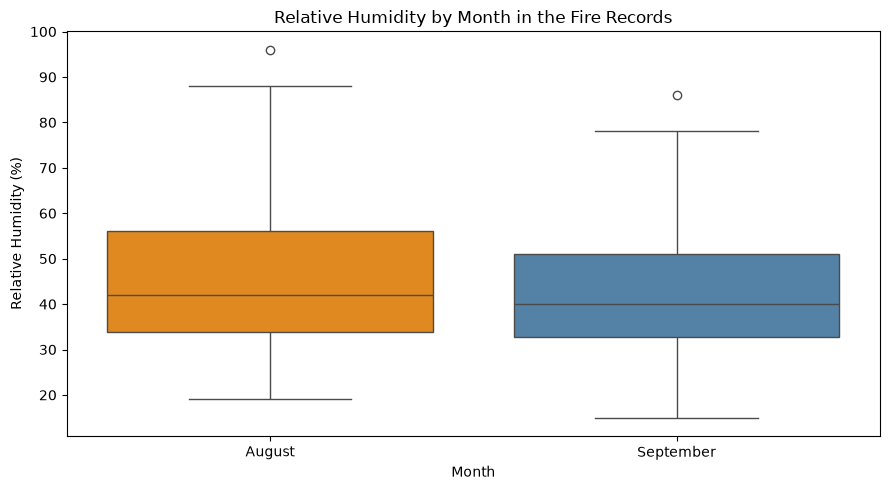

In [22]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=humidity_df, x="month_name", y="RH", hue="month_name",
    order=["August", "September"], hue_order=["August", "September"],
    palette={"August": "darkorange", "September": "steelblue"}, legend=False
)
plt.title("Relative Humidity by Month in the Fire Records")
plt.xlabel("Month")
plt.ylabel("Relative Humidity (%)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: August's median is 42% and September's is 40%. Their means are 45.49% and 42.84%. The middle 50% runs from 33.75% to 56% in August and 32.75% to 51% in September. The IQRs are 22.25 and 18.25 percentage points. These fit the visual estimates and show only a small center difference with lots of overlap. The histogram shows the high-humidity tails, while the boxes show medians and middle spreads more clearly.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [23]:
humidity_df.groupby("month_name")["RH"].agg(["count", "min", "max"])


,count,min,max
month_name,,,
August,184,19,96
September,172,15,86


In [24]:
fires_df.loc[
    [humidity_df["RH"].idxmin(), humidity_df["RH"].idxmax()],
    ["X", "Y", "month", "day", "RH"]
]


,X,Y,month,day,RH
85,1,2,sep,thu,15
211,7,4,aug,sat,96


In [25]:
print("Original August and September rows:", fires_df["month"].isin(["aug", "sep"]).sum())
print("Rows used:", len(humidity_df))
print("Month labels used:", humidity_df["month_name"].unique())


Original August and September rows: 356
Rows used: 356
Month labels used: <ArrowStringArray>
['August', 'September']
Length: 2, dtype: str


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: If humidity was below 0% or over 100%, I'd think something was wrong. I checked the original data, and the lowest value was 15% in September and the highest was 96% in August. August is 19% to 96%, and September is 15% to 86%, which matches the plots. All 184 August rows and 172 September rows are still there, so I didn't have to fix or remove anything. I still can't tell if every reading in the file was right.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: August's 184 records have a median humidity of 42%, compared with 40% in September's 172 records. August also has a wider IQR, 22.25 versus 18.25 percentage points. The distributions overlap heavily, but August is slightly higher, not lower as predicted.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: The difference isn't that big, so it doesn't mean August is always more humid. It also doesn't prove humidity caused the fires. The data only comes from fires in one park, not all the weather for those months. Some of the records might be from the same day or area too.


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does wind speed, in km/h, differ between August and September fire records in this dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I expect similar wind speeds and a lot of overlap. The months are close together, and wind can change a lot within either month.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use August and September records with wind speed in km/h. Other months are excluded. There are no missing wind values, so no selected rows are dropped. Each analyzed row is one fire record with a weather reading. Month labels are added in wind_df and the original data stays unchanged.


In [26]:
wind_df = fires_df.loc[
    fires_df["month"].isin(["aug", "sep"]), ["month", "wind"]
].copy()
wind_df = wind_df.dropna(subset=["wind"])
wind_df["month_name"] = wind_df["month"].map({"aug": "August", "sep": "September"})
wind_df.head()


,month,wind,month_name
5,aug,5.4,August
6,aug,3.1,August
7,aug,2.2,August
8,sep,5.4,September
9,sep,4.0,September


In [27]:
wind_df["month_name"].value_counts().reindex(["August", "September"])


month_name
August       184
September    172
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


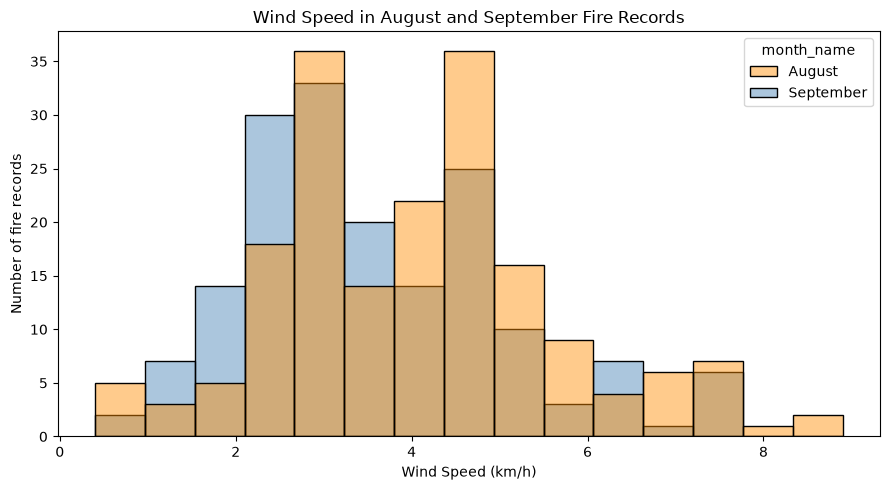

In [28]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=wind_df, x="wind", hue="month_name",
    hue_order=["August", "September"], bins=15, common_bins=True,
    palette={"August": "darkorange", "September": "steelblue"}, alpha=0.45
)
plt.title("Wind Speed in August and September Fire Records")
plt.xlabel("Wind Speed (km/h)")
plt.ylabel("Number of fire records")
plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Most wind readings are roughly 2 to 5 km/h in both months. August looks centered near 4 km/h and September near 3 to 3.5. The bars are uneven, with several peaks, and both groups extend toward higher speeds. August reaches about 9 km/h and September about 8. There is lots of overlap. Their counts are close, 184 versus 172, but the larger August group can still have taller bars.


In [29]:
wind_summary = wind_df.groupby("month_name")["wind"].describe().reindex(["August", "September"])
wind_summary.round(2)


,count,mean,std,min,25%,50%,75%,max
month_name,,,,,,,,
August,184.0,4.09,1.64,0.4,2.7,4.00,4.9,8.9
September,172.0,3.56,1.54,0.9,2.2,3.35,4.5,7.6


In [30]:
wind_iqr = wind_summary["75%"] - wind_summary["25%"]
wind_iqr


month_name
August       2.2
September    2.3
dtype: float64

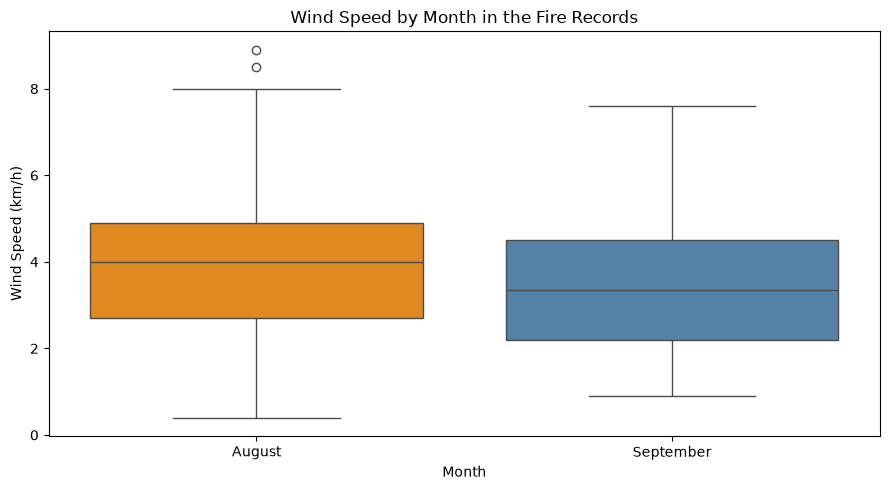

In [31]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=wind_df, x="month_name", y="wind", hue="month_name",
    order=["August", "September"], hue_order=["August", "September"],
    palette={"August": "darkorange", "September": "steelblue"}, legend=False
)
plt.title("Wind Speed by Month in the Fire Records")
plt.xlabel("Month")
plt.ylabel("Wind Speed (km/h)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: August's median is 4.00 km/h and its mean is 4.09. September's median is 3.35 km/h and its mean is 3.56. The middle 50% runs from 2.7 to 4.9 km/h in August and 2.2 to 4.5 in September. Their IQRs are close, 2.2 and 2.3 km/h. The box plot shows the small center shift and similar middle spreads. The histogram shows the uneven peaks that the boxes hide.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [32]:
wind_df.groupby("month_name")["wind"].agg(["count", "min", "max"])


,count,min,max
month_name,,,
August,184,0.4,8.9
September,172,0.9,7.6


In [33]:
fires_df.loc[
    [wind_df["wind"].idxmin(), wind_df["wind"].idxmax()],
    ["X", "Y", "month", "day", "wind"]
]


,X,Y,month,day,wind
249,3,4,aug,wed,0.4
142,8,6,aug,fri,8.9


In [34]:
print("Original August and September rows:", fires_df["month"].isin(["aug", "sep"]).sum())
print("Rows used:", len(wind_df))
print("Month labels used:", wind_df["month_name"].unique())


Original August and September rows: 356
Rows used: 356
Month labels used: <ArrowStringArray>
['August', 'September']
Length: 2, dtype: str


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: Negative wind speeds would not make sense. The original records confirm the selected minimum of 0.4 km/h and maximum of 8.9, both in August. September ranges from 0.9 to 7.6 km/h. These match the plotted ranges. All 356 selected records are still included, split into 184 and 172. I kept the high readings instead of removing them just because the box plot marks them as unusual.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: August's 184 records have a slightly higher median wind speed, 4.00 versus 3.35 km/h for September's 172 records. Their IQRs are similar at 2.2 and 2.3 km/h, with lots of overlap. This mostly fits the prediction of similar distributions, although August's center is a bit higher.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: This doesn't mean August always has stronger wind, or that wind caused the fires. The data is only from fires in one park, so it doesn't include every windy day. There aren't exact dates, and I also can't see wind direction or gusts in the file.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I did use AI to specificlly check my code on node 18 just to make sure I had done it correctly, which it confirmed I did it right, but suggested a longer way to do it, which I disregarded.


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
